:::{admonition} Run this notebook yourself!
:class: important

Download the executed notebook: **{nb-download}`penalty_visual_diversity.ipynb`**!

Run it in your browser: **{binder}`penalty_visual_diversity.ipynb`**!

:::

(penalty-visual-diversity)=
# Using penalties to incentivize visual diversity

[](how-to-penalty) showed the basics of working with custom penalty functions, but their flexibility allows for us to bias stimulus synthesis in a wide variety of different ways. In this notebook, we will show how they can be used to increase perceptual diversity among metamers for the {class}`~plenoptic.models.LuminanceGainControl` model. We will also demonstrate how changing the initial image used for synthesis affects the resulting metamers, and how these two effects interact.

:::{seealso}

The authors of plenoptic presented a poster which talked about this idea (among others) at the [Cognitive Computational Neuroscience 2026](https://2026.ccneuro.org/) conference. See {cite:alp}`Broderick2026-biasing-optim` (poster available [here](https://dx.doi.org/10.17605/OSF.IO/R7JPS)) for more details.

:::

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import torch

import plenoptic as po

# so that relative sizes of axes created by po.plot.imshow and others look right
plt.rcParams["figure.dpi"] = 72

# We will not run synthesis in this notebook, instead loading cached results
cached_metamers = po.data.fetch_data("visual_diversity_penalty.tar.gz")

  0%|                                   | 1.02k/13.2M [00:01<3:34:33, 1.02kB/s]

Untarring contents of '/home/jenkins/agent/workspace/CCN_neurorse_plenoptic_PR-501/.cache/plenoptic/visual_diversity_penalty.tar.gz' to '/home/jenkins/agent/workspace/CCN_neurorse_plenoptic_PR-501/.cache/plenoptic/visual_diversity_penalty.tar.gz.untar'


:::{admonition} This notebook retrieves cached synthesis results / Reproducibility
:class: warning dropdown

Instead of performing synthesis for all examples in this notebook, we have cached the result of most of these syntheses online and download them for display.

This notebook contains collapsible admonitions which contain the steps necessary to run synthesis yourself after each call to {func}`~plenoptic.Metamer.load`. If you have a GPU available, the only synthesis calls that take longer than a minute are those which use DISTS, in the final section (if you do not have a GPU, they will all take longer).

If you wish to exactly reproduce our results, you will also need to do the following:
- Call `torch.use_deterministic_algorithms(True)`. This only needs to be done once.
- Set the seed to 0: `po.set_seed(0)`. The seed only affects the initialization of the metamer attribute as a patch of noise. It should thus be done either before the call to {func}`torch.rand_like` in the creation of `init_img` and `init_img_curie`, as we show below.

See [](reproduce-best-practices) for more details.
:::

The following hidden cells defines a function we'll use to visualize our metamer synthesis results, expand it for more details.

In [2]:
def create_metamer_figure(met, titles=None):
    n_cols = len(met.image) + 1
    zoom = 256 // met.image.shape[-1]
    fig = plt.figure(figsize=(5.2 * n_cols, 10.4))
    gs = mpl.gridspec.GridSpec(2, n_cols, figure=fig)
    im_axes = [fig.add_subplot(gs[0, i]) for i in range(n_cols)]
    im_axes += [fig.add_subplot(gs[1, i]) for i in range(n_cols)]
    # met.image has more than one dimension, but they're all identical, so just use the
    # first. image[:1] is the same as image[0], but preserves the number of dimensions.
    imgs = torch.cat([met.image[:1], met.metamer])
    # get the representation of those images
    reps = met.model(imgs)
    titles = ["Target image"] + [
        f"Model metamer[{i}]" for i in range(met.metamer.shape[0])
    ]
    titles += ["Representation of target"] + [
        f"Representation of metamer[{i}]" for i in range(met.metamer.shape[0])
    ]
    for ax, im, t in zip(im_axes, torch.cat([imgs, reps]), titles):
        # ensure all have the same vrange
        vr = (0, 1) if "Representation" not in t else (0.68, 0.71)
        po.plot.imshow(im.unsqueeze(0), ax=ax, title=t, zoom=zoom, vrange=vr)
        ax.xaxis.set_visible(False)
        ax.yaxis.set_visible(False)
    return fig

## Metamer synthesis without custom penalty

### Synthesizing a single metamer

Throughout this notebook, we'll use the {class}`~plenoptic.models.LuminanceGainControl` model, which convolves its input with a center-surround filter, applies gain control / divisive normalization, and then rectifies the output. Thus, the model is sensitive only to mid-range frequencies and is insensitive to absolute pixel values.

In [3]:
model = po.models.LuminanceGainControl(
    31, pretrained=True, pad_mode="circular", cache_filt=True
).eval()
po.remove_grad(model)
model.to(torch.float64)

LuminanceGainControl(
  (center_surround): CenterSurround()
  (luminance): Gaussian()
)

Before we start writing custom penalties, let's see what the default behavior is. By default, {class}`~plenoptic.Metamer` uses {func}`plenoptic.regularize.penalize_range` as the penalty function (to keep the metamer image's pixel values between 0 and 1). let's start by synthesizing a single {class}`~plenoptic.models.LuminanceGainControl` metamer with this default behavior and then move on to synthesizing two such metamers simultaneously.

Below, we create our target image, `img`. We start with a picture of Einstein and downsample it by a factor of 2 (this makes the high-frequency patterns generated in much of the following examples more obvious). We will also create a sample of uniform noise with the same shape as `img` to use to initialize synthesis. Note that this is the default behavior in plenoptic; we're doing it explicitly here so that we can visualize and examine this tensor separately.

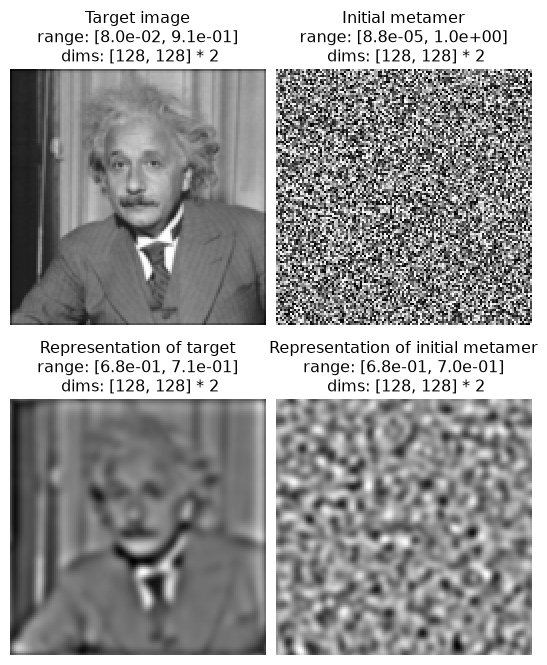

In [4]:
img = po.data.einstein().to(torch.float64)
img = po.process.blur_downsample(img)
init_img = torch.rand_like(img)
title = [
    "Target image",
    "Initial metamer",
    "Representation of target",
    "Representation of initial metamer",
]
po.plot.imshow(
    [img, init_img, model(img), model(init_img)], col_wrap=2, zoom=2, title=title
);

The above figure shows the target image in the first column, followed by the noise sample we'll use to initialize synthesis. The second row shows the model representation of both images. Over the course of {class}`~plenoptic.Metamer` synthesis, plenoptic will update the pixels of the top right image so as to make the two bottom images match.

By comparing the top and bottom images in the left column, we can understand our model a little better. The model representation looks like a modified version of the input:
- It looks blurred, as our model has thrown away the highest frequencies.
- It looks "grayer": since our model only cares about contrast, not luminance, it throws away absolute pixel value and only captures how those pixels change over a small distance.

We will now pass `img` and `model` <!-- skip-lint --> along with the loss function {func}`plenoptic.loss.l2_norm` (rather than the default, plenoptic.loss.mse; using {func}`~plenoptic.loss.l2_norm` improves the quality of our resulting metamer) to initialize our {class}`~plenoptic.Metamer` object, call {meth}`~plenoptic.Metamer.setup` to set the initial image, and call {meth}`~plenoptic.Metamer.synthesize`:

  0%|          | 0/1000 [00:00<?, ?it/s]

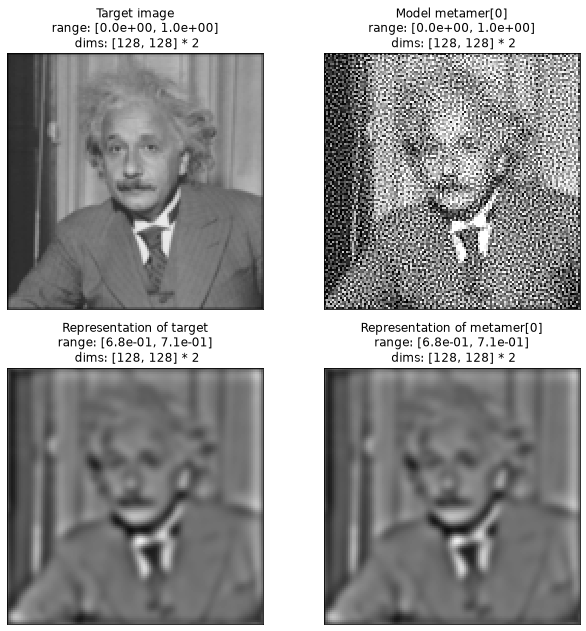

In [5]:
simple_met = po.Metamer(img, model, po.loss.l2_norm)
simple_met.setup(initial_image=init_img)
simple_met.synthesize(1000, stop_criterion=1e-16)
create_metamer_figure(simple_met);

The above figure is set up like the previous one, and we can see now that the two images in the bottom row are identical. Thus, metamer synthesis has succeeded and we've synthesized a model metamer. The metamer looks like the target image of Einstein, except with lots of high frequency noise added and, if you look carefully, the finer details (e.g., in his hair) removed. Additionally, the image looks a little brighter (that is, the average pixel values are a little higher).

### Synthesizing two metamers simultaneously

Now that we understand what one metamer looks like, let's see what happens when we synthesize two of them.
Our default penalty, {func}`~plenoptic.regularize.penalize_range` does nothing to encourage multiple metamers to be different (or similar) to each other, so let's see how synthesis behaves when we use it!

We could synthesize two metamers sequentially, initializing with different patches of white noise. In this notebook, we will synthesize both metamers simultaneously, taking advantage of the fact that {class}`~plenoptic.models.LuminanceGainControl` (like the other models in plenoptic) operates on each element in the batch dimension independently:

In [6]:
# Test that our model independently operates on these images
test_imgs = torch.cat([po.data.einstein(), po.data.curie()])
test_imgs = test_imgs.to(torch.float64)
rep = model(test_imgs)
print(f"Input shape: {test_imgs.shape}")
print(f"Output shape: {rep.shape}")
# Check that the batch 0 of the joint output is the same as the output on the 0th image
assert (rep[0] == model(test_imgs[0])).all()
# and for index 1 as well
assert (rep[1] == model(test_imgs[1])).all()

Input shape: torch.Size([2, 1, 256, 256])
Output shape: torch.Size([2, 1, 256, 256])


Let's {meth}`~torch.Tensor.repeat` our image along the batch dimension so we have two identical copies. We will then create a new initialization tensor, two independent samples of uniform noise:

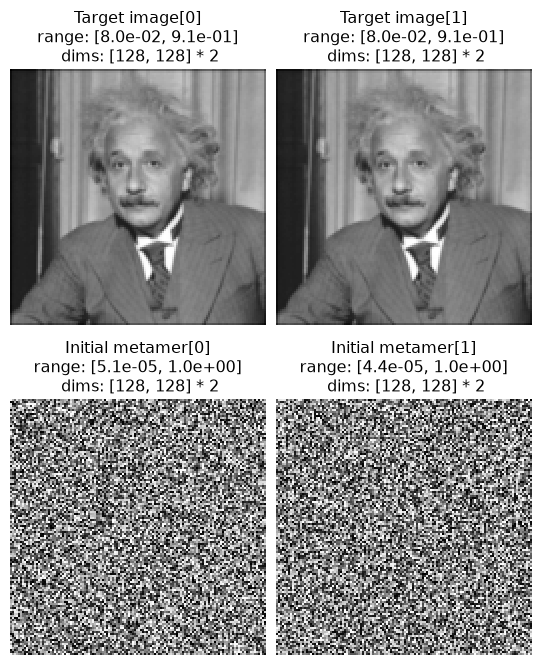

In [7]:
img = img.repeat(2, 1, 1, 1)
po.set_seed(0)
init_img = torch.rand_like(img)
title = [
    "Target image[0]",
    "Target image[1]",
    "Initial metamer[0]",
    "Initial metamer[1]",
]
po.plot.imshow([img, init_img], col_wrap=2, zoom=2, title=title);

In the figure above, we can see our target and initial images. Over the course of synthesis, plenoptic will update the pixels of the bottom image in each column so that the model representation matches that of the top.

The two images in the top row are identical, but the two in the bottom are not! Humans aren't very sensitive to the differences between independent samples of noise at this resolution, so they look pretty similar (I have to focus pretty hard in specific locations in order to find the differences). But in fact, on a pixel-by-pixel basis, these two initial images are more different from each other than they are from the target, which we can see by computing the mean-squared error:

In [8]:
init_diff = po.loss.mse(init_img[0], init_img[1])
print(f"MSE between indepedendent noise samples: {init_diff}")
img_diff = po.loss.mse(init_img[0], img[0])
print(f"MSE between Einstein image and noise: {img_diff}")

MSE between indepedendent noise samples: 0.1674598395760851
MSE between Einstein image and noise: 0.10514815534750115


Okay, with all that out of the way, let's initialize our {class}`~plenoptic.Metamer` object as before. Note everything is the same here, except that the shape of `img` has changed. We then load in and visualize the results of this synthesis:

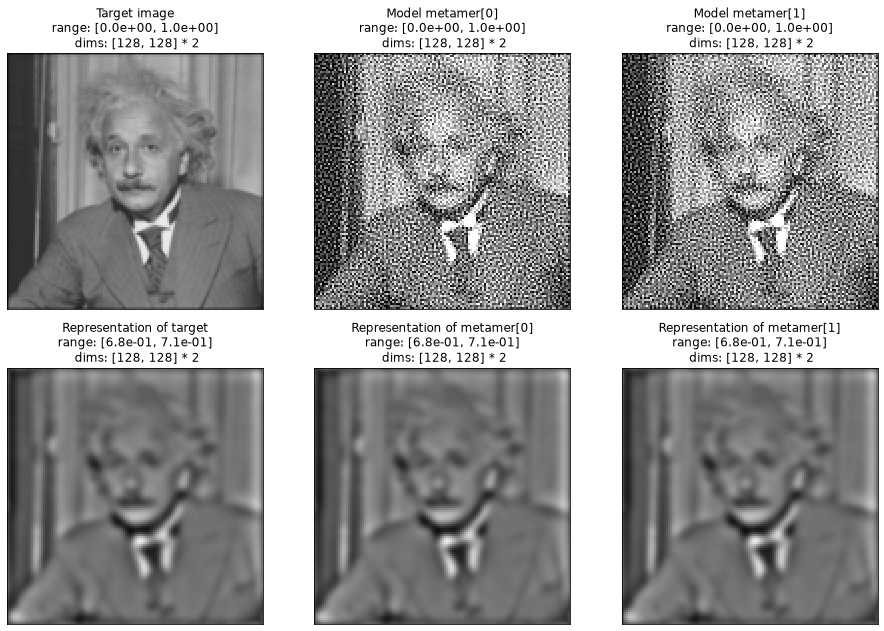

In [9]:
met_basic = po.Metamer(img, model, po.loss.l2_norm)
met_basic.load(cached_metamers / "vis_div_penalty_basic.pt", map_location="cpu")
create_metamer_figure(met_basic);

:::{admonition} How to run this synthesis manually
:class: dropdown note

<!-- TestVisualDiversityPenalty.test_basic -->
```{code-block} python
met_basic.setup(initial_image=init_img)
met_basic.synthesize(1000, stop_criterion=1e-16)
```
:::

In the above figure, we can see the target image in the first column, followed by the two independent metamer images. The second row shows the model representation of each image in the top row, and you can see that they're all identical -- that is, metamer synthesis has succeeded and we've found two new metamers. The metamers both look like the target image of Einstein, except with lots of high frequency noise added and, if you look carefully, the finer details (e.g., in his hair) removed. Additionally, the image looks a little brighter (that is, the average pixel values are a little higher).

A little farther up, I just demonstrated that the fact that two images of this resolution look similar to humans is no guarantee that they are *actually* similar, so let's compute the mean-squared error between all the model representations:

In [10]:
rep_diff = po.loss.mse(model(met_basic.image[0]), model(met_basic.metamer[0]))
print(f"MSE between target and metamer[0] representations: {rep_diff}")
rep_diff = po.loss.mse(model(met_basic.image[0]), model(met_basic.metamer[1]))
print(f"MSE between target and metamer[1] representations: {rep_diff}")
rep_diff = po.loss.mse(model(met_basic.metamer[0]), model(met_basic.metamer[1]))
print(f"MSE between metamer[0] and metamer[1] representations: {rep_diff}")

MSE between target and metamer[0] representations: 2.1692016550037166e-10
MSE between target and metamer[1] representations: 1.4778060202894466e-10


MSE between metamer[0] and metamer[1] representations: 3.37312933025444e-10


You can see that these are all really small numbers! However, we have no point of comparison --- are these small enough to consider these images metamers? Let's compute the mean-squared error between the representations of some other images for comparison:

In [11]:
rep_diff = po.loss.mse(model(met_basic.image[:1]), model(init_img[:1]))
print(f"MSE between target and initial[0] representations: {rep_diff}")
nat_img = po.process.blur_downsample(po.data.curie().to(torch.float64))
rep_diff = po.loss.mse(model(met_basic.image[:1]), model(nat_img))
print(f"MSE between representations of two different natural images: {rep_diff}")

MSE between target and initial[0] representations: 1.3510293406017787e-05


MSE between representations of two different natural images: 3.350024931162494e-05


We can see that the MSE between the representation of the target and our metamers is several orders of magnitude smaller than that between two different natural images or a natural image and a sample of noise. Thus, we'll conclude they are metamers. Note that we're not going to compute the MSEs between the representations for the rest of these notebooks, but if you compute them yourselves, you'll see that they are similarly small.

:::{seealso}
In your own experiments, the question of whether model outputs are close enough for the synthesized image(s) to be considered metamers is one that you should give careful thought to. See [](feather-synthesis-success) and [](good-enough) for more discussion of what this means in practice.
:::

Okay, now that we're convinced these are metamers, scroll back up and look at those two metamers again --- they look really perceptually similar! Again, they're not actually that similar on a pixel-by-pixel basis, as we can clarify by computing the mean-squared error between them:

In [12]:
met_diff = po.loss.mse(met_basic.metamer[0], met_basic.metamer[1])
print(f"MSE between metamers: {met_diff}")

MSE between metamers: 0.09708081576801837


That's less than 10% smaller than the MSE between the target Einstein image and one of those samples of noise. But they do look really similar! This leads to the question: do all metamers for this model look like this? Or is this a result of our optimization procedure and the choices we made?

## Changing the initialization point

One simple way to try to find more visually-diverse metamers is to change the image used to initialize the synthesis procedure, as done by {cite:alp}`Broderick2025-foveat-metam`. In plenoptic, we can do that by creating an appropriately-shaped tensor and passing it to {func}`plenoptic.Metamer.setup` (as seen in the dropdown below). Let's create an initial image tensor that contains one sample of white noise and a picture of Marie Curie:

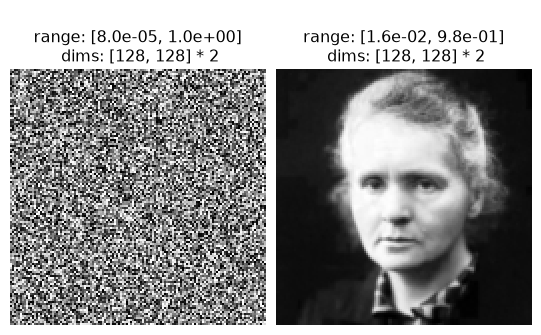

In [13]:
po.set_seed(0)
curie = po.process.blur_downsample(po.data.curie())
white_noise = torch.rand_like(curie)
init_img_curie = torch.cat([white_noise, curie])
po.plot.imshow(init_img_curie, zoom=2);

By changing where metamer synthesis starts, we affect where it ends up. That's because metamer synthesis is a high-dimensional non-convex optimization problem, the solutions of which are often dependent upon their initialization. There is (likely) a huge set of potential metamers for any given model, and so we're hoping that by choosing two starting points which appear very different, that our final metamers will also appear more distinct. As above, we initialize the {class}`~plenoptic.Metamer` object with the same target image, model, and loss, and then load and visualize our cached results:

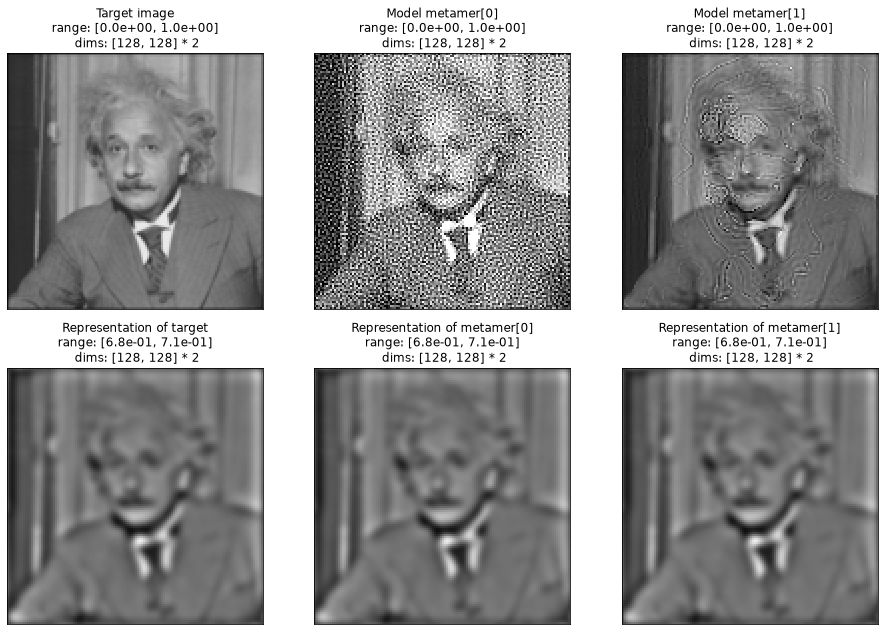

In [14]:
met_curie = po.Metamer(img, model, po.loss.l2_norm)
met_curie.load(cached_metamers / "vis_div_penalty_basic_curie.pt", map_location="cpu")
create_metamer_figure(met_curie);

:::{admonition} How to run this synthesis manually
:class: dropdown note

<!-- TestVisualDiversityPenalty.test_basic_curie -->
```{code-block} python
met_curie.setup(initial_image=init_img_curie)
met_curie.synthesize(1000, stop_criterion=1e-16)
```
:::

The figure above has the same layout as before. As before, we can see that all three images in the bottom row are identical, and thus the three images in the top row are all metamers. The first metamer, in the second column, looks the same as the result from the default metamer synthesis: the target with high-frequency noise. The second, however, looks fairly different: it looks like a slightly blurred version of the target image with a faint outline of Marie Curie's face living in the highest frequencies, and the overall image looks a little darker than the target. All of those features are a result of our initialization: the initial image was dark everywhere except for the center and metamer synthesis has preserved the highest frequencies found in the initial image. In the first metamer, those preserved high frequencies show up as the noise pattern, and in the second, as the outline of Curie's face.

While this setting of the initialization to find visually different metamers works, let's see what we can accomplish if we choose the {attr}`~plenoptic.Metamer.penalty_function` to find more visually distinct metamers. Doing so is akin to shrinking the space of possible metamer images, and can be done in tandem with setting the initial image.

:::{seealso}
See [](adversarial-examples-metamer) for a very different use of the effect of penalty functions and initialization on {class}`~plenoptic.Metamer` synthesis, in order to synthesize an adversarial example for the ResNet50 deep neural network.
:::

## Using {attr}`~plenoptic.Metamer.penalty_function` to find visually distinct metamers

In this section, we will create custom penalty functions to encourage our two simultaneously-synthesized metamers to be more perceptually different from each other. The question we must ask ourselves is thus "what do we mean by 'perceptually different'?" Here, we'll show three examples from two different types of penalties. First, we will construct a penalty which encourages the metamers to have different spectral energy densities, taking advantage of the fact that spectral energy is a low-level image property which human perception is very sensitive to. Second, we will develop a penalty which makes use of a metric from the field of [Image Quality Assessment](https://en.wikipedia.org/wiki/Image_quality), DISTS ({cite:alp}`Ding2020-image-qualit-asses`), which was developed to predict human ratings of image quality on image distortion databases containing texture and non-texture images.

For both types of penalties, we are taking advantage of pre-existing knowledge of the human visual system to construct penalties which we believe will encourage pairs to metamers to "look different". The first penalty takes advantage of the basic fact that human visual perception is sensitive to spectral energy, while the second exploits the knowledge encoded within a published image quality metric.

Note that we are not claiming that our choices here are "the best" in any way --- you are encouraged to try tweaking the spectral energy penalty, try out different image quality metrics, or develop your own completely novel penalties! If you find something interesting, please [let us know!](https://github.com/plenoptic-org/plenoptic/discussions/new?category=show-and-tell)

### Encourage different energy spectral density

Looking at the metamers synthesized from the white noise initialization at the top of this notebook, we can see that both are dominated by high frequencies present in the initial images. This suggests that one effective way to make them appear different from each other would be to encourage their [energy spectral density](https://en.wikipedia.org/wiki/Spectral_density#Energy_spectral_density) to differ, so that their spatial frequency content is as different as possible.

To do so, we will write two helper functions:
- `spyr_energy` uses {class}`~plenoptic.process.SteerablePyramidFreq` to compute the average energy in different spatial frequency / orientation bands, represented as a tensor of shape `(batch, bands)`.
- `construct_mask` returns a boolean mask tensor of the same shape; its `True` values define the bands we will use to compute the penalty value. It accepts a string determining what mask to use, and currently only accepts `"low"` or `"vertical"`, the two examples shown here. Feel free to modify it to accept other values!

:::{seealso}

See {class}`~plenoptic.process.SteerablePyramidFreq` or [](ps-steer-pyr) to learn more about the steerable pyramid.

:::

In [15]:
pyr = po.process.SteerablePyramidFreq(img.shape[-2:], is_complex=True)
pyr.to(img.dtype)


def spyr_energy(x):
    # after this, x is a dictionary whose keys specify the scale and whose values are
    # tensors of shape (batch, channel, orientation, height, width) containing the
    # coefficients at that scale (note that the height/width changes across scales).
    if not isinstance(x, dict):
        x = pyr(x)
    # Compute the average energy in each steerable pyramid band, averaging over height
    # and width.
    energy = [v.abs().mean(dim=(-2, -1)) for v in x.values()]
    # concatenate into a single vector, of shape (batch, scales * orientations + 2),
    # where the two extra elements are the residuals. Our input images are grayscale and
    # thus our coefficients have only a single channel, which we flatten.
    energy = torch.cat([p.flatten(1, -1) for p in energy], 1)
    return energy


def construct_mask(x, include):
    # get dictionary of coefficients. after this, mask will be a dictionary like x
    # described in spyr_energy above
    mask = pyr(x)
    if "low" in include:
        # zero out high frequencies, all orientations
        for scale in ["residual_highpass", 0, 1, 2]:
            mask[scale] = torch.zeros_like(mask[scale])
    elif "vertical" in include:
        # zero out all non-vertical orientations, all frequencies
        for scale in mask:
            if scale in ["residual_highpass", "residual_lowpass"]:
                # zero out residuals entirely.
                mask[scale] = torch.zeros_like(mask[scale])
            else:
                # for non-residuals, values are tensors of shape (batch, channel,
                # orientation, height, width). The vertical orientation is the first
                # element in that dimension, so we are setting the values for all other
                # orientations in the coefficient tensor to 0.
                mask[scale][:, :, 1:] = 0
    # After this, mask is a tensor of shape (batch, bands) where the excluded bands are
    # zero and the included bands have non-zero values
    mask = spyr_energy(mask)
    # We then convert this tensor to boolean, so that the included bands are True and
    # the excluded False.
    return mask.to(bool)

#### Different vertical energy

Now let's use the above functions to define a penalty to encourage the vertically-oriented energy to be different between the two images. In the following:
- we compute a mask to select only the vertical bands
- we compute the squared difference in the mask-selected bands across the two images
- we convert this difference (a non-negative value we want to maximize) to a penalty (a value bounded between 0 and 1 that we want to minimize) by passing this value to `torch.exp(-x)` (as explained in [Designing a well-behaved penalty function](penalty-well-behaved))
- we combine this penalty with the default range penalty

There are two tricks in the following code worth noting:
- We normalize the metamers' spectral energy by that of the target image (`target_energy`). This is because the magnitude of the steerable pyramid coefficients vary across spatial frequency bands, and we want each to have roughly the same impact on the penalty.
- We care about efficiency, so we compute `mask` and `target_energy` in advance. That way, when `vertical_penalty` is called on each iteration of synthesis, it needs to compute as little as possible.

In [16]:
# Compute vertical mask
mask = construct_mask(img, "vertical")
# Compute average energy of target image, to normalize. this is useful because the
# steerable pyramid coefficients have different magnitudes across scales and we want
# each band to have approximately the same contribution
target_energy = spyr_energy(img)


def steerpyr_penalty(x, mask, target_energy):
    # compute the average energy in each band of our synthesized images
    penalty = spyr_energy(x)
    # normalize that by the target energy and use the mask to select only the bands we
    # care about
    penalty = mask * (penalty / target_energy)
    # Compute the average squared difference in energy between the two synthesized
    # images
    penalty = torch.mean(penalty.diff(dim=0).pow(2))
    # Convert this distance to a penalty by using torch.exp(-x)
    penalty = torch.exp(-penalty)
    # Add this to range penalty
    return po.regularize.penalize_range(x) + penalty


# We don't want to compute the mask and target energy in the penalty function itself,
# since they are the same across all of synthesis
def vertical_penalty(x):
    return steerpyr_penalty(x, mask, target_energy)

We now have a penalty function which accepts a single tensor and returns a scalar. We can see that it is encouraging proper behavior by comparing its values on the two sets of metamers we have already computed:

In [17]:
basic_penalty = vertical_penalty(met_basic.metamer).item()
print(f"Penalty on noise-init metamer pair: {basic_penalty}")
curie_penalty = vertical_penalty(met_curie.metamer).item()
print(f"Penalty on noise/curie-init metamer pair: {curie_penalty}")

Penalty on noise-init metamer pair: 0.999917736628498
Penalty on noise/curie-init metamer pair: 0.798994756976523


As we can see, it returns a higher value for the pair whose images were both initialized by noise than the other. While two images initialized with noise will have very different mean-squared error, they will have roughly comparable spectral energy, which is quite different from that of natural images --- that's the rationale for this penalty!

In [18]:
# Check that our mask is the same as the one in the tests, which is what generates the
# saved metamers
saved_mask = torch.load(
    po.data.fetch_data("spyr_mask.tar.gz") / "spyr_mask_vertical.pt", map_location="cpu"
)
assert (saved_mask == mask).all()

1.02kB [00:01, 805B/s]

Untarring contents of '/home/jenkins/agent/workspace/CCN_neurorse_plenoptic_PR-501/.cache/plenoptic/spyr_mask.tar.gz' to '/home/jenkins/agent/workspace/CCN_neurorse_plenoptic_PR-501/.cache/plenoptic/spyr_mask.tar.gz.untar'


Okay, let's see what the effect of using this penalty is on the synthesized metamers. The call to {meth}`~plenoptic.Metamer.setup` and {meth}`~plenoptic.Metamer.synthesize` are the same as in our earlier examples, the only difference is that we set {attr}`~plenoptic.Metamer.penalty_function` and {attr}`~plenoptic.Metamer.penalty_lambda` in the initialization:

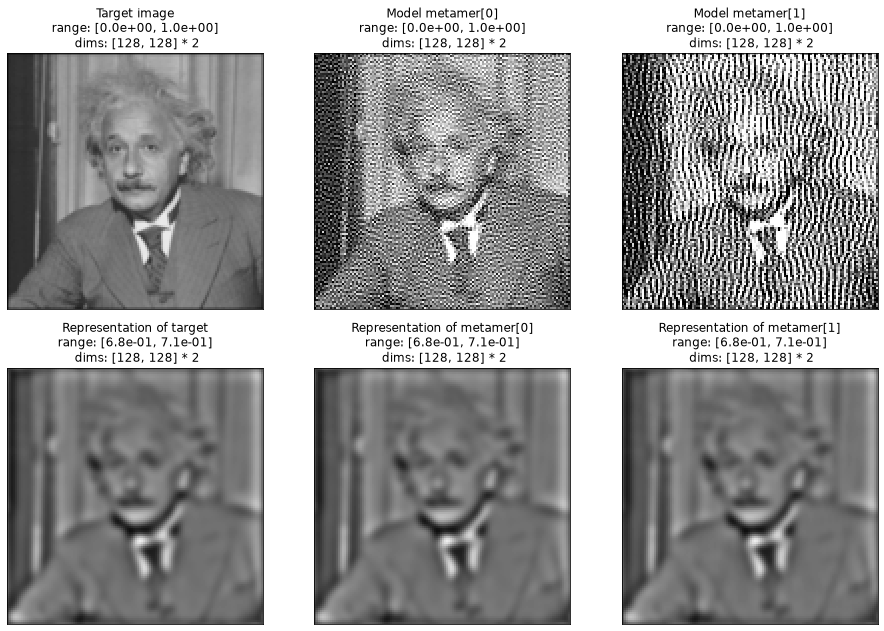

In [19]:
met = po.Metamer(
    img,
    model,
    po.loss.l2_norm,
    penalty_function=vertical_penalty,
    penalty_lambda=0.1,
)
met.load(cached_metamers / "vis_div_penalty_vertical.pt", map_location="cpu")
create_metamer_figure(met);

:::{admonition} How to run this synthesis manually
:class: dropdown note

<!-- TestVisualDiversityPenalty.test_vertical -->
```{code-block} python
met.setup(initial_image=init_img)
met.synthesize(1000, stop_criterion=1e-16)
```
:::

The figure above has the same layout as before, and we can see that all three images in the bottom row are identical, and thus the three images in the top row are all metamers. These two metamers look quite different, both from each other and from the previous ones we've synthesized. Here, the high frequencies in the second metamer appear more pronounced than in the first, and are concentrated vertically, while the high frequencies appear slightly muted in the first metamer.

We can do the exact same thing while initializing with the image of Marie Curie:

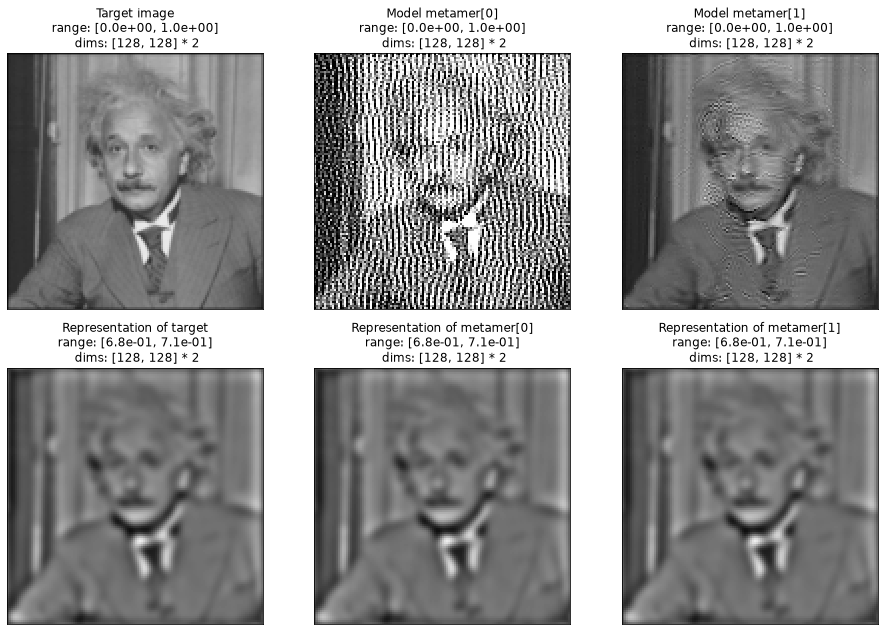

In [20]:
met = po.Metamer(
    img,
    model,
    po.loss.l2_norm,
    penalty_function=vertical_penalty,
    penalty_lambda=0.1,
)
met.load(cached_metamers / "vis_div_penalty_vertical_curie.pt", map_location="cpu")
create_metamer_figure(met);

:::{admonition} How to run this synthesis manually
:class: dropdown note

<!-- TestVisualDiversityPenalty.test_vertical_curie -->
```{code-block} python
met.setup(initial_image=init_img_curie)
met.synthesize(1000, stop_criterion=1e-16)
```
:::

Here, the two effects we've seen so far seem to both be present. The first metamer looks like the "vertical" metamer initializing with noise, while the second looks like the Curie-initialized metamer with the default penalty. As mentioned above, this Curie-intialized metamer already has fairly distinct spectral energy from the noise-initialized one, and exaggerating the vertical power in the first metamer has increased this effect.

#### Different low frequency energy

We can do the same thing using a different mask which selects the low frequency bands across all orientations:

In [21]:
# Compute low frequency mask
mask = construct_mask(img, "low")


# This is the same as vertical_penalty, we're just using a different mask
def low_penalty(x):
    return steerpyr_penalty(x, mask, target_energy)

In [22]:
# Check that our mask is the same as the one in the tests, which is what generates the
# saved metamers
saved_mask = torch.load(
    po.data.fetch_data("spyr_mask.tar.gz") / "spyr_mask_low.pt", map_location="cpu"
)
assert (saved_mask == mask).all()

Let's use this penalty to synthesize some metamers. For this synthesis, in order to successfully find metamers, we need to lower {attr}`~plenoptic.Metamer.penalty_lambda` slightly and run synthesis for a longer time:

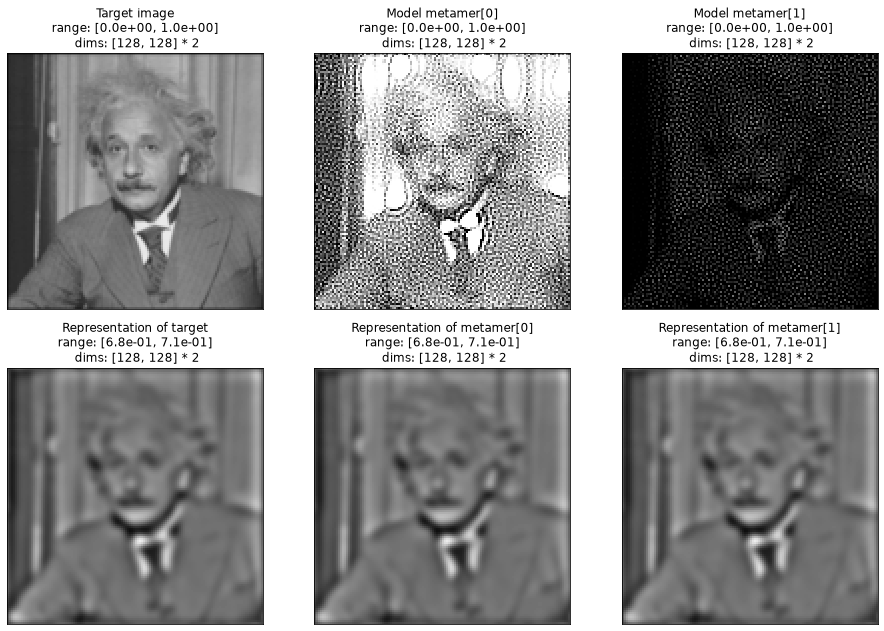

In [23]:
met = po.Metamer(
    img,
    model,
    po.loss.l2_norm,
    penalty_function=low_penalty,
    penalty_lambda=0.07,
)
met.load(cached_metamers / "vis_div_penalty_low.pt", map_location="cpu")
create_metamer_figure(met);

:::{admonition} How to run this synthesis manually
:class: dropdown note

<!-- TestVisualDiversityPenalty.test_low -->
```{code-block} python
met.setup(initial_image=init_img)
met.synthesize(3000, stop_criterion=1e-16)
```
:::

The above figure has the same layout as before, and we again see that the images in the bottom row are identical, so those in the top are all model metamers. Unlike the previous examples we've seen, neither of the resulting metamers look like those that result from the default settings. Instead, the results here are exploiting the fact that {class}`~plenoptic.models.LuminanceGainControl` is insensitive to the absolute pixel values and so the two metamers have very different apparent brightness levels (this information is captured in the residual lowpass of {class}`~plenoptic.process.SteerablePyramidFreq`, which is included in the mask used for this penalty). The first, brighter metamer also appears to have a faint two cycles per image horizontal grating on top of it (you may have to squint and move away from your screen to see it), though this is much less salient than the brightness difference.

We can again use this same penalty when initializing metamer synthesis with the noise / Marie Curie pair. Successful metamer synthesis requires lowering {attr}`~plenoptic.Metamer.penalty_lambda` still further:

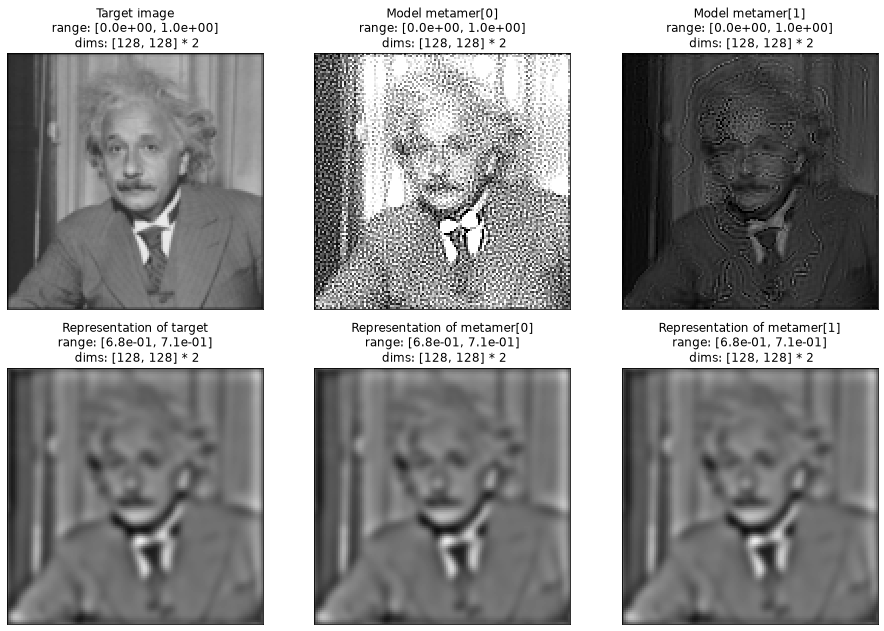

In [24]:
met = po.Metamer(
    img,
    model,
    po.loss.l2_norm,
    penalty_function=low_penalty,
    penalty_lambda=0.05,
)
met.load(cached_metamers / "vis_div_penalty_low_curie.pt", map_location="cpu")
create_metamer_figure(met);

:::{admonition} How to run this synthesis manually
:class: dropdown note

<!-- TestVisualDiversityPenalty.test_low_curie -->
```{code-block} python
met.setup(initial_image=init_img_curie)
met.synthesize(3000, stop_criterion=1e-16)
```
:::

The resulting metamer pair looks similar to the noise-initialized one with the same penalty. However, comparing the darker image to the one from the earlier pair highlights an interesting feature: this synthesis setup still results in metamers whose high frequencies are largely inherited from their initialization, unlike those resulting from `vertical_penalty`: the darker metamer in this pair still appears to have the faint outline of Marie Curie's face, as we've seen in the other Curie-initialized metamers in this notebook, while the darker metamer in the noise-initialized pair has the salt-and-pepper high frequency pattern seen in the other noise-initialized metamers.

In this example, since neither the {class}`~plenoptic.models.LuminanceGainControl` model nor `low_penalty` are sensitive to high frequencies, the patterns in those frequencies are still largely due to their initialization.

### Maximize an image quality metric

:::{admonition} pyiqa
:class: attention

[pyiqa](https://iqa-pytorch.readthedocs.io/en/latest/) must be installed in your environment to run the rest of this notebook: run `pip install pyiqa` (or the equivalent) in your virtual environment.

:::

In the previous section, we created our penalty by looking at the model metamers and reasoning through visual properties we thought could be used to separate them.

An alternative approach is to look for existing functions which take in pairs of images and return a measure of their perceptual distance, i.e., how different humans consider them to be. One source for these functions is the field of Image Quality Assessment (IQA), which (among other things) develops [Full-Reference methods](https://en.wikipedia.org/wiki/Image_quality#Objective_methods) that meet this description.

Several of the metrics included in plenoptic's {ref}`metrics-api` module (e.g., {func}`plenoptic.metric.ssim`) come from this field, but we can also make use of the separate package [pyiqa](https://iqa-pytorch.readthedocs.io/en/latest/), which contains plenoptic-compatible pytorch implementations of a variety of IQA methods!

:::{warning}

IQA is largely concerned with whether image capturing, processing, storage, etc. methods (such as compression) leads to perceptually noticeable distortions in the resulting image. Their methods have thus largely been developed with the assumption that one of the two images being compared is a "clean" / unaltered image and the other is some distorted version of the clean image.

There is thus a chance that such functions will lead to nonsensical results on two completely unrelated images (as is common in plenoptic), so be careful!

:::

Here, we'll make use of DISTS ({cite:alp}`Ding2020-image-qualit-asses`), a full-reference IQA model which combines aspect of texture and structure similarity. We grab the metric object from pyiqa and then create a penalty function making use of it.

In [25]:
import pyiqa

# after this call, metric is a torch Module (similar to plenoptic's models), and so we
# treat it as such. See pyiqa documentation for more details.
metric = pyiqa.create_metric("dists", device=img.device, as_loss=True)
po.remove_grad(metric)
metric.to(img.dtype)


def dists(x):
    # the metric object accepts two 4d tensors; this is equivalent to
    # metric(x[0].unsqueeze(0), x[-1].unsqueeze(0)), to ensure that we convert one
    # tensor of shape (2, c, h, w) to two tensors of shape (1, c, h, w)
    return metric(x[:1], x[-1:])


def dists_penalty(x):
    return po.regularize.penalize_range(x) + torch.exp(-dists(x))

Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/DISTS_weights-f5e65c96.pth" to /home/jenkins/agent/workspace/CCN_neurorse_plenoptic_PR-501/.cache/torch/hub/pyiqa/DISTS_weights-f5e65c96.pth



  0%|          | 0.00/12.0k [00:00<?, ?B/s]

100%|██████████| 12.0k/12.0k [00:00<00:00, 14.5MB/s]

Loading pretrained model DISTS from /home/jenkins/agent/workspace/CCN_neurorse_plenoptic_PR-501/.cache/torch/hub/pyiqa/DISTS_weights-f5e65c96.pth


Note that, as with our earlier penalty, we use the same `torch.exp(-x)` trick to convert a distance (a non-negative value we wish to maximize) into a penalty (a value bounded between 0 and 1 that we wish to minimize).

This metamer synthesis is slightly more difficult and requires a [multi-stage synthesis](multi-stage-penalty), where we first synthesize the metamer pair without a custom penalty and then use that as a starting point for a second synthesis using `dists_penalty` (expand the dropdown below to see this all written out).

:::{seealso}
See [the datasaurus dozen star example](ds-star) for a different use of multi-stage synthesis.
:::

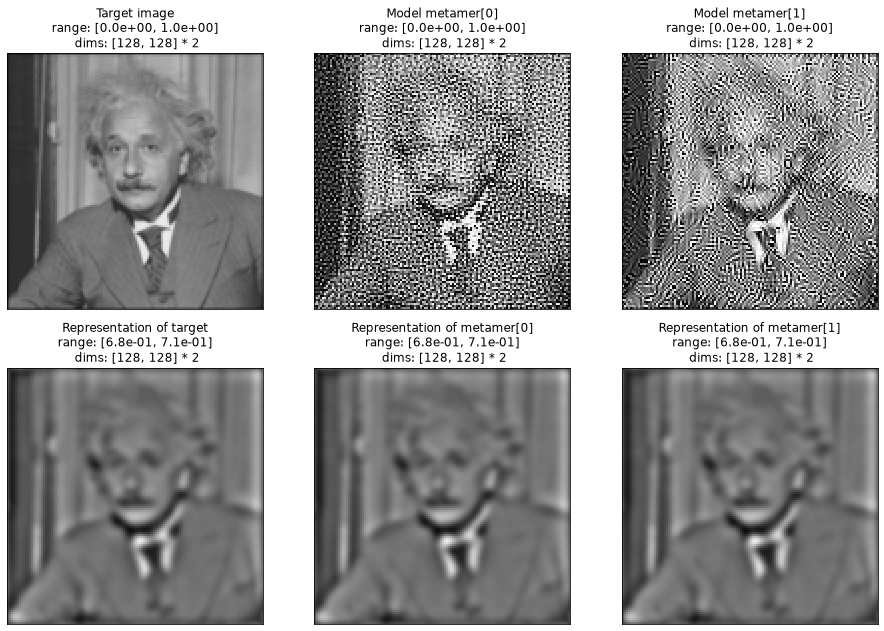

In [26]:
met_penalty = po.Metamer(
    img,
    model,
    po.loss.l2_norm,
    penalty_function=dists_penalty,
    penalty_lambda=0.5,
)
met_penalty.load(cached_metamers / "vis_div_penalty_dists.pt", map_location="cpu")
create_metamer_figure(met_penalty);

:::{admonition} How to run this synthesis manually
:class: dropdown note

<!-- TestVisualDiversityPenalty.test_dists -->
```{code-block} python
met = po.Metamer(img, lg_model, po.loss.l2_norm)
met.setup(initial_image=init_img)
met.synthesize(500, stop_criterion=1e-16)

met_penalty = po.Metamer(
    img,
    lg_model,
    po.loss.l2_norm,
    penalty_function=dists_penalty,
    penalty_lambda=0.5,
)
met_penalty.setup(initial_image=met.metamer, optimizer_kwargs={"lr": 0.03})
met_penalty.synthesize(500, stop_criterion=1e-16)
```
:::

The above figure has the same layout as before, and we again see that the images in the bottom row are identical, so those in the top are all model metamers. The first metamer looks the same as the ones resulting from default behavior, but the high frequencies in the second metamer have been organized into some sort of pattern, with longer straight and curved contours visible.

We can use this same penalty when we initialize metamer synthesis from the noise/Curie-initialized pair, which uses the same multi-stage procedure as the noise-initialized pair:

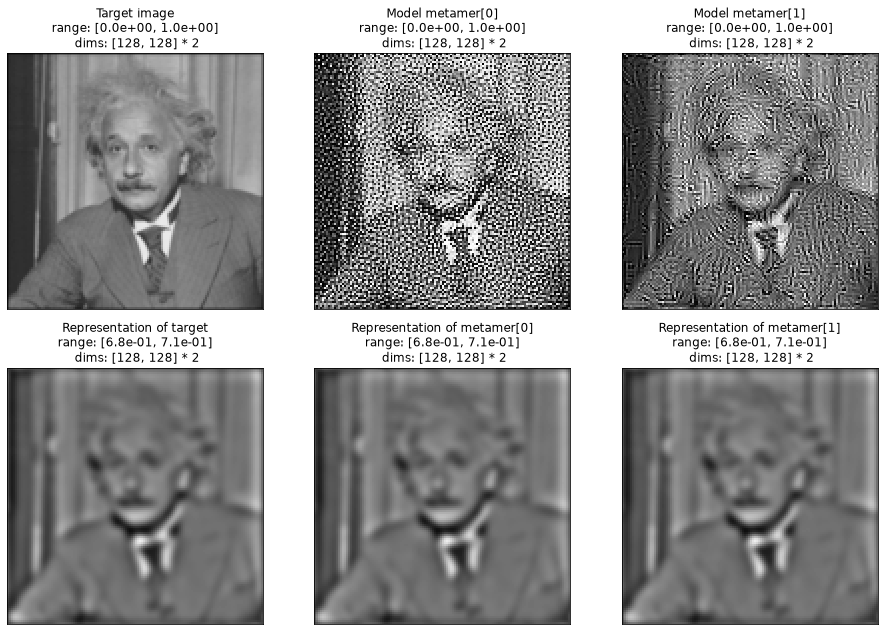

In [27]:
met_penalty = po.Metamer(
    img,
    model,
    po.loss.l2_norm,
    penalty_function=dists_penalty,
    penalty_lambda=0.5,
)
met_penalty.load(cached_metamers / "vis_div_penalty_dists_curie.pt", map_location="cpu")
create_metamer_figure(met_penalty);

:::{admonition} How to run this synthesis manually
:class: dropdown note

<!-- TestVisualDiversityPenalty.test_dists_curie -->
```{code-block} python
met = po.Metamer(img, lg_model, po.loss.l2_norm)
met.setup(initial_image=init_img_curie)
met.synthesize(500, stop_criterion=1e-16)

met_penalty = po.Metamer(
    img,
    lg_model,
    po.loss.l2_norm,
    penalty_function=dists_penalty,
    penalty_lambda=0.5,
)
met_penalty.setup(initial_image=met.metamer, optimizer_kwargs={"lr": 0.03})
met_penalty.synthesize(500, stop_criterion=1e-16)
```
:::

Initialization has a much smaller effect on the appearance of this metamer pair than in our previous examples: the second metamer appears to be darker than in the noise-initialized pair, and if I refer back to original image of Marie Curie's face, I can convince myself that some of the curved contours around Einstein's face are the result of this initialization, but the effect is much less obvious.

## Conclusion

In this notebook, we've walked through how we can write custom penalty functions or make use of existing IQA methods in order to incentive pairs of metamers to be more visually distinctive from each other. We have also shown how a similar goal can be achieved by changing synthesis initialization, and how these two factors interact.

We started with the goal of synthesizing pairs of images that are more visually distinct, and then took advantage of existing knowledge of the human visual system in order to construct penalties which focused on specific perceptually-relevant image properties that were ignored by the model. When constructing penalties for your own {class}`~plenoptic.Metamer` synthesis problems, you should similarly think specifically about which properties that your model is ignoring you would like to manipulate, and come up with a function that encodes these properties. Then: experiment!